In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
import pandas as pd
from collections import Counter

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import pandas as pd
import numpy as np

#Load data
df = pd.read_csv(r"C:\vscode\AIT NLP grammar& spelling\combined_grammar_spelling_pairs.csv")
input_texts = df["input"].astype(str).tolist()
target_texts = ['<start> ' + text + ' <end>' for text in df["target"].astype(str).tolist()]

#Special tokens (ensure consistency)
special_tokens = ['<pad>', '<start>', '<end>', '<OOV>']

#Initialize tokenizer
tokenizer = Tokenizer(num_words=10000, oov_token='<OOV>', filters='!"#$%&()*+,-./:;=?@[\\]^_`{|}~\t\n')

#Fit tokenizer on combined text
tokenizer.fit_on_texts(input_texts + target_texts)

#Manually force <pad> token to be index 0 (for mask_zero=True to work)
tokenizer.word_index = {k: (v+1) for k, v in tokenizer.word_index.items()}  # shift all indices by +1
tokenizer.word_index['<pad>'] = 0  # set <pad> to index 0
tokenizer.index_word = {v: k for k, v in tokenizer.word_index.items()}

#Update vocab size after adjustments
vocab_size = min(len(tokenizer.word_index), tokenizer.num_words) + 1  # +1 for safety (index starts at 0)

#Tokenize
input_sequences = tokenizer.texts_to_sequences(input_texts)
target_sequences = tokenizer.texts_to_sequences(target_texts)

#Padding
max_input_len = max(len(seq) for seq in input_sequences)
max_target_len = max(len(seq) for seq in target_sequences)

input_padded = pad_sequences(input_sequences, maxlen=max_input_len, padding='post')
target_padded = pad_sequences(target_sequences, maxlen=max_target_len, padding='post')

# Prepare decoder input and output
decoder_input_data = target_padded[:, :-1]
decoder_target_data = target_padded[:, 1:]

print(f"Vocabulary size: {vocab_size}")
print(f"Max input length: {max_input_len}, Max target length: {max_target_len}")


Vocabulary size: 10001
Max input length: 70, Max target length: 75


In [ ]:
# Split into training and validation sets
from sklearn.model_selection import train_test_split

encoder_input_train, X_temp, decoder_input_train, decoder_input_temp, decoder_target_train, decoder_target_temp = train_test_split(
    input_padded, decoder_input_data, decoder_target_data, test_size=0.2, random_state=42
)

encoder_input_val, encoder_input_test, decoder_input_val, decoder_input_test, decoder_target_val, decoder_target_test = train_test_split(
    X_temp, decoder_input_temp, decoder_target_temp, test_size=0.5, random_state=42
)

Vocabulary size: 10001
Max input length: 70, Max target length: 75
Training samples: 31300
Validation samples: 3912
Test samples: 3913


In [11]:
#input sequence (incorrect sentence) into a context vector

@tf.keras.utils.register_keras_serializable() #Register custom classes for serialization
class Encoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, enc_units, **kwargs):
        super(Encoder, self).__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.enc_units = enc_units
        self.embedding = Embedding(vocab_size, embedding_dim, mask_zero=True)
        self.lstm = LSTM(enc_units, return_sequences=True, return_state=True)

    def call(self, x, training=False):
        x = self.embedding(x)
        outputs, state_h, state_c = self.lstm(x, training=training)
        return outputs, state_h, state_c  # outputs = all hidden states
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.vocab_size,
            "embedding_dim": self.embedding_dim,
            "enc_units": self.enc_units
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


In [12]:
@tf.keras.utils.register_keras_serializable()
class BahdanauAttention(tf.keras.layers.Layer):
    def __init__(self, units, **kwargs):
        super(BahdanauAttention, self).__init__(**kwargs)
        self.units = units
        self.W1 = Dense(units)  # for encoder output
        self.W2 = Dense(units)  # for decoder hidden state
        self.V = Dense(1)       # to produce attention scores

    def call(self, decoder_hidden, encoder_outputs):
        decoder_hidden_time_axis = tf.expand_dims(decoder_hidden, 1)  # (batch_size, 1, hidden_size)
        score = self.V(tf.nn.tanh(self.W1(encoder_outputs) + self.W2(decoder_hidden_time_axis)))  # (batch_size, seq_len, 1)
        attention_weights = tf.nn.softmax(score, axis=1)  # (batch_size, seq_len, 1)

        context_vector = attention_weights * encoder_outputs  # (batch_size, seq_len, hidden_size)
        context_vector = tf.reduce_sum(context_vector, axis=1)  # (batch_size, hidden_size)

        return context_vector, attention_weights
    
    def get_config(self):
        config = super().get_config()
        config.update({"units": self.units})
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [13]:
#generates the corrected sentence from the context vector
# Decoder with attention
@tf.keras.utils.register_keras_serializable()
class Decoder(tf.keras.Model):
    def __init__(self, vocab_size, embedding_dim, dec_units, **kwargs):
        super(Decoder, self).__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.dec_units = dec_units
        self.embedding = Embedding(vocab_size, embedding_dim, mask_zero=True)
        self.lstm = LSTM(dec_units, return_sequences=True, return_state=True)
        self.attention = BahdanauAttention(dec_units)
        self.fc = Dense(vocab_size, activation='softmax') 

    def call(self, x, initial_state, encoder_outputs, training=False):
        x = self.embedding(x)  

        #decoder_hidden = tf.concat(initial_state, axis=-1)

        context_vector, attention_weights = self.attention(initial_state[0], encoder_outputs)
        context_vector = tf.expand_dims(context_vector, 1)
        context_vector = tf.tile(context_vector, [1, tf.shape(x)[1], 1])


        # Concatenate context with embedded decoder input
        x = tf.concat([context_vector, x], axis=-1)

        # Run through LSTM
        output, state_h, state_c = self.lstm(x, initial_state=initial_state, training=training)

        # Final output layer to generate probabilities
        output = self.fc(output)

        if training:
            return output
        else:
            return output, state_h, state_c, attention_weights

    def get_config(self):
        config = super().get_config()
        config.update({
            "vocab_size": self.vocab_size,
            "embedding_dim": self.embedding_dim,
            "dec_units": self.dec_units
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [14]:
@tf.keras.utils.register_keras_serializable()
class Seq2Seq(tf.keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super(Seq2Seq, self).__init__()
        self.encoder = encoder
        self.decoder = decoder

    def call(self, inputs, training=False):
        encoder_input, decoder_input = inputs

        encoder_outputs, state_h, state_c = self.encoder(encoder_input)
        decoder_outputs, _, _, _ = self.decoder(
            decoder_input, [state_h, state_c], encoder_outputs, training=training
        )
        return decoder_outputs
    
    def get_config(self):
        config = super().get_config()
        config.update({
            "encoder": tf.keras.saving.serialize_keras_object(self.encoder),
            "decoder": tf.keras.saving.serialize_keras_object(self.decoder),
        })
        return config

    @classmethod
    def from_config(cls, config):
        encoder = tf.keras.saving.deserialize_keras_object(config["encoder"])
        decoder = tf.keras.saving.deserialize_keras_object(config["decoder"])
        return cls(encoder=encoder, decoder=decoder)

In [18]:
#Hyperparameters
embedding_dim = 128
lstm_units = 256
vocab_size = vocab_size  

#Instantiate encoder and decoder
encoder = Encoder(vocab_size, embedding_dim, lstm_units)
decoder = Decoder(vocab_size, embedding_dim, lstm_units)

#Define inputs
encoder_inputs = Input(shape=(max_input_len,), name="encoder_input")
decoder_inputs = Input(shape=(max_target_len - 1,), name="decoder_input") #-1 is for teacher forcing

#Connect encoder
encoder_outputs, state_h, state_c = encoder(encoder_inputs)
#Connect decoder with attention
decoder_outputs, _, _, _ = decoder(decoder_inputs, [state_h, state_c], encoder_outputs)

#Build model
attn_seq2seq = Model([encoder_inputs, decoder_inputs], decoder_outputs)
attn_seq2seq.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
attn_seq2seq.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 70)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 74)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_3 (Encoder) │ [(None, 70, 256), │  1,674,368 │ encoder_input[0]… │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_3 (Decoder) │ [(None, 74,       │  4,638,610 │ decoder_input[0]… │
│                     │ 10001), (None,    │            │ encoder_3[0][1],  │
│                     │ 256), (None,      │            │ encoder_3[0][2],  │
│                     │ 256), (None, 70,  │            │ encoder_3[0][0]   │
│                     │ 1)]               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 6,312,978 (24.08 MB)

 Trainable params: 6,312,978 (24.08 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = attn_seq2seq.fit(
    [encoder_input_train, decoder_input_train],
    decoder_target_train,
    validation_data=([encoder_input_val, decoder_input_val], decoder_target_val),
    batch_size=32,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 900s 916ms/step - accuracy: 0.9374 - loss: 0.8612 - val_accuracy: 0.9692 - val_loss: 0.2237
Epoch 2/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 901s 920ms/step - accuracy: 0.9715 - loss: 0.2025 - val_accuracy: 0.9699 - val_loss: 0.2075
Epoch 3/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 901s 921ms/step - accuracy: 0.9714 - loss: 0.1919 - val_accuracy: 0.9708 - val_loss: 0.1972
Epoch 4/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 904s 924ms/step - accuracy: 0.9725 - loss: 0.1791 - val_accuracy: 0.9718 - val_loss: 0.1875
Epoch 5/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 900s 920ms/step - accuracy: 0.9733 - loss: 0.1680 - val_accuracy: 0.9723 - val_loss: 0.1785
Epoch 6/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 898s 918ms/step - accuracy: 0.9743 - loss: 0.1554 - val_accuracy: 0.9729 - val_loss: 0.1713
Epoch 7/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 899s 918ms/step - accuracy: 0.9756 - loss: 0.1432 - val_accuracy: 0.9738 - val_loss: 0.1638
Epoch 8/20
979/979 ━━━━━━━━━━━━━━━━━━━━ 946s 966ms/step - accuracy: 0.9771 -

In [20]:
attn_seq2seq.save("seq2seq_model.keras")

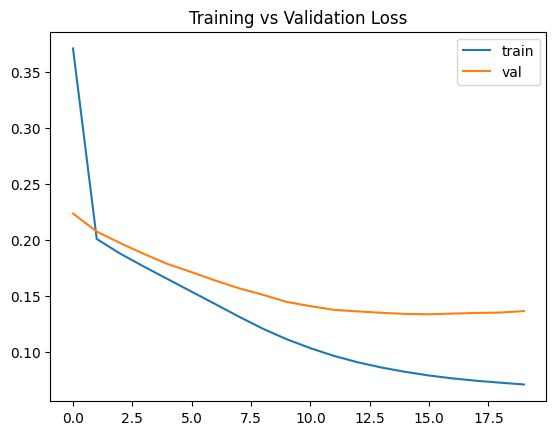

In [21]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title('Training vs Validation Loss')
plt.show()


In [ ]:
def predict_sentence(input_text, tokenizer, encoder, decoder, max_input_len, max_target_len=50):
    input_seq = tokenizer.texts_to_sequences([input_text])
    input_seq = pad_sequences(input_seq, maxlen=max_input_len, padding='post')

    input_seq_tensor = tf.convert_to_tensor(input_seq)
    
    #Encoder
    encoder_outputs, state_h, state_c = encoder(input_seq_tensor)

    #Decoder 
    start_token = tokenizer.word_index['<start>']
    end_token = tokenizer.word_index['<end>']
    decoder_input = tf.constant([[start_token]])
    
    decoded_sentence = []

    #Decoder step by step prediction
    for _ in range(max_target_len):
        predictions, state_h, state_c, _ = decoder(decoder_input, [state_h, state_c], encoder_outputs)
        
        predicted_id = tf.argmax(predictions[:, -1, :], axis=-1).numpy()[0]
        predicted_word = tokenizer.index_word.get(predicted_id, '<OOV>')

        if predicted_word == '<end>' or predicted_word == '<pad>':
            break
        
        decoded_sentence.append(predicted_word)

        decoder_input = tf.constant([[predicted_id]])

    return ' '.join(decoded_sentence)


In [ ]:
test_input = "i go to shcool everydaay"
output = predict_sentence(test_input, tokenizer, encoder, decoder, max_input_len)
print(f"\nInput     : {test_input}")
print(f"Predicted : {output}")



Input     : i go to shcool everydaay
Predicted : i think our lives are more


In [24]:
def predict_sequence(input_seq, tokenizer, encoder, decoder, max_target_len=50):
    input_seq = tf.convert_to_tensor(input_seq)
    encoder_outputs, state_h, state_c = encoder(input_seq)

    target_seq = tf.constant([[tokenizer.word_index['<start>']]])
    decoded_sentence = []

    for _ in range(max_target_len):
        output_tokens, state_h, state_c, attention = decoder(
            target_seq, [state_h, state_c], encoder_outputs, training=False
        )

        sampled_token_index = tf.argmax(output_tokens[:, -1, :], axis=-1).numpy()[0]
        sampled_word = tokenizer.index_word.get(sampled_token_index, '<OOV>')

        if sampled_word == '<end>' or sampled_word == '<pad>':
            break

        decoded_sentence.append(sampled_word)
        target_seq = tf.constant([[sampled_token_index]])

    return decoded_sentence


In [ ]:
N = 10
test_inputs = encoder_input_test[:N]
references = []
hypotheses = []

for i in range(N):
    input_seq = np.expand_dims(test_inputs[i], axis=0)
    pred_words = predict_sequence(input_seq, tokenizer, encoder, decoder)

    target_seq = decoder_target_test[i]
    target_words = [tokenizer.index_word.get(idx, '') for idx in target_seq if idx > 0]
    if '<end>' in target_words:
        target_words = target_words[:target_words.index('<end>')]

    references.append([target_words])     
    hypotheses.append(pred_words)       

    print(f"\nInput     : {' '.join([tokenizer.index_word.get(idx, '') for idx in encoder_input_test[i] if idx > 0])}")
    print(f"Reference : {' '.join(target_words)}")
    print(f"Predicted : {' '.join(pred_words)}")



Input     : he was born in oulmender
Reference : he was born in altimeter
Predicted : he was born in grant

Input     : i visited <OOV> last year
Reference : i visited pretend last year
Predicted : i visited <OOV> last year

Input     : <OOV> is a beautiful country
Reference : conscious is a beautiful country
Predicted : <OOV> is a beautiful country

Input     : i visited <OOV> last year
Reference : i visited intelligent last year
Predicted : i visited <OOV> last year

Input     : he was born in exceptial
Reference : he was born in acceptable
Predicted : he was born in grant

Input     : they live in <OOV>
Reference : they live in criticism
Predicted : they live in <OOV>

Input     : they live in <OOV>
Reference : they live in ecstasy
Predicted : they live in <OOV>

Input     : <OOV> is a beautiful country
Reference : immediately is a beautiful country
Predicted : <OOV> is a beautiful country

Input     : it is not much less frequent though and it still fulfills the needs that we have

In [ ]:
import nltk
from nltk.translate.bleu_score import corpus_bleu, sentence_bleu, SmoothingFunction

smoothie = SmoothingFunction().method4
bleu_score = corpus_bleu(references, hypotheses, smoothing_function=smoothie)

print(f"\nCorpus BLEU Score (on {N} samples): {bleu_score:.4f}")


Corpus BLEU Score (on 10 samples): 0.7434
